### 사전에 구현된 모델
### ImageNet-1000(1k)
: 딥러닝 모델의 이미지 분류 학습에 사용되는 대규모 이미지 데이터 셋<br>
강아지, 고양이, 자동차, 새, 비행기, 과일 등 다양한 종류의 이미가 있음.

- 클래스 수 : 1000개
- 학습이미지 : 약 128만장
- 이미지 크기 : 다양한 크기

In [ ]:
%pip install torchinfo

In [2]:
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import models, transforms
import matplotlib.pyplot as plt
from torchinfo import summary

In [ ]:
weights = models.ResNet50_Weights.IMAGENET1K_V2
load_model = models.resnet50(weights=weights)
print(load_model)

In [4]:
load_model.eval()
with torch.no_grad():
    print(load_model(torch.randn(2,3,224,224)).shape)

torch.Size([2, 1000])


In [5]:
# 모델의 전체 구조, 각 층의 출력 크기, 파라미터 개수, 연산량 등을 확인하는 함수
summary(load_model, input_size=(2,3,224,224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [2, 1000]                 --
├─Conv2d: 1-1                            [2, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [2, 64, 112, 112]         128
├─ReLU: 1-3                              [2, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [2, 64, 56, 56]           --
├─Sequential: 1-5                        [2, 256, 56, 56]          --
│    └─Bottleneck: 2-1                   [2, 256, 56, 56]          --
│    │    └─Conv2d: 3-1                  [2, 64, 56, 56]           4,096
│    │    └─BatchNorm2d: 3-2             [2, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [2, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [2, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [2, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [2, 64, 56, 56]           --
│ 

In [16]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize(size=(256)),
    transforms.CenterCrop(size=(224,224))
])

In [ ]:
# meta는 사전학습된 가중치에 대한 부가정보를 딕셔너리 형태로 저장하고 있다
print(weights.meta.keys())

dict_keys(['min_size', 'categories', 'num_params', 'recipe', '_metrics', '_ops', '_file_size', '_docs'])


In [8]:
idx2label = dict(enumerate(weights.meta['categories']))
print(idx2label)

{0: 'tench', 1: 'goldfish', 2: 'great white shark', 3: 'tiger shark', 4: 'hammerhead', 5: 'electric ray', 6: 'stingray', 7: 'cock', 8: 'hen', 9: 'ostrich', 10: 'brambling', 11: 'goldfinch', 12: 'house finch', 13: 'junco', 14: 'indigo bunting', 15: 'robin', 16: 'bulbul', 17: 'jay', 18: 'magpie', 19: 'chickadee', 20: 'water ouzel', 21: 'kite', 22: 'bald eagle', 23: 'vulture', 24: 'great grey owl', 25: 'European fire salamander', 26: 'common newt', 27: 'eft', 28: 'spotted salamander', 29: 'axolotl', 30: 'bullfrog', 31: 'tree frog', 32: 'tailed frog', 33: 'loggerhead', 34: 'leatherback turtle', 35: 'mud turtle', 36: 'terrapin', 37: 'box turtle', 38: 'banded gecko', 39: 'common iguana', 40: 'American chameleon', 41: 'whiptail', 42: 'agama', 43: 'frilled lizard', 44: 'alligator lizard', 45: 'Gila monster', 46: 'green lizard', 47: 'African chameleon', 48: 'Komodo dragon', 49: 'African crocodile', 50: 'American alligator', 51: 'triceratops', 52: 'thunder snake', 53: 'ringneck snake', 54: 'hogn

In [12]:
idx2label[30]

'bullfrog'

In [ ]:
%pip install imageio

<class 'numpy.ndarray'>
(708, 1071, 3)
<class 'torch.Tensor'>
torch.Size([3, 224, 224])
torch.Size([1, 3, 224, 224])


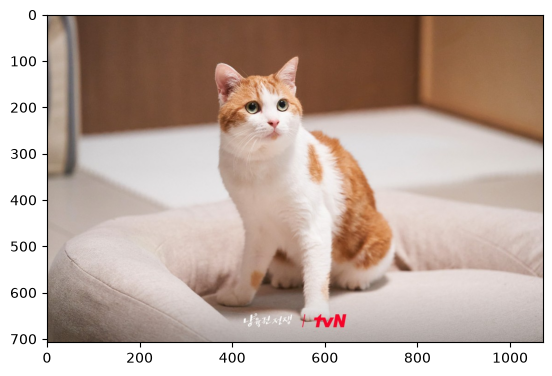

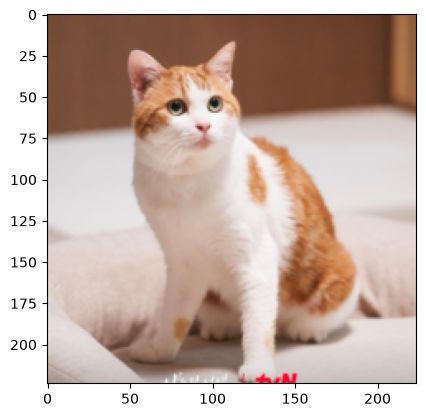

In [18]:
import imageio.v2 as imageio

X = imageio.imread('https://cdn.news.koreanbar.or.kr/news/photo/202509/34214_26713_5731.jpg')
print(type(X))
print(X.shape)
plt.imshow(X)

X = transform(X)
print(type(X))
print(X.shape)
plt.figure()
plt.imshow(X.permute(1,2,0))

X = X.unsqueeze(dim=0)
print(X.shape)

In [ ]:
load_model.eval()
with torch.no_grad():
    y_hat_sorted = load_model(X).sort(descending=True)